In [ ]:
# CSET485 - AI and Society
# Assignment 1: German Credit Data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
# Load the German Credit dataset from the UCI repository

# Column names for the 20 attributes and the target
column_names = [
    "checking_account", "duration", "credit_history", "purpose",
    "credit_amount", "savings", "employment", "installment_rate",
    "personal_status_sex", "other_debtors", "residence_since",
    "property", "age", "other_installment_plans", "housing",
    "existing_credits", "job", "dependents", "telephone",
    "foreign_worker", "credit_class"
]

# The original file has no header and uses whitespace separators
url = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/statlog/german/german.data"
)

df = pd.read_csv(
    url,
    sep=r"\s+",
    header=None,
    names=column_names
)

# Display the first five records
display(df.head())


# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Check for missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Examine the target variable
print("\nCredit class distribution:")
print(df["credit_class"].value_counts())



,checking_account,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,credit_class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


Dataset shape: (1000, 21)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   checking_account         1000 non-null   object
 1   duration                 1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   savings                  1000 non-null   object
 6   employment               1000 non-null   object
 7   installment_rate         1000 non-null   int64 
 8   personal_status_sex      1000 non-null   object
 9   other_debtors            1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  property                 1000 non-null   object
 12  age                      1000 non-null   int64 
 13  other_installment_plans  1000 non-null   objec

In [ ]:
# Count missing values in every column
print("Missing values:")
print(df.isnull().sum())

# Summary statistics for numerical columns
print("\nNumerical summary:")
display(df.describe())

# Check possible outliers in selected numerical columns
numerical_columns = [
    "duration", "credit_amount", "age",
    "installment_rate", "residence_since",
    "existing_credits", "dependents"
]

for column in numerical_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} potential outliers")

Missing values:
checking_account           0
duration                   0
credit_history             0
purpose                    0
credit_amount              0
savings                    0
employment                 0
installment_rate           0
personal_status_sex        0
other_debtors              0
residence_since            0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
dependents                 0
telephone                  0
foreign_worker             0
credit_class               0
dtype: int64

Numerical summary:


,duration,credit_amount,installment_rate,residence_since,age,existing_credits,dependents,credit_class
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,1.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,2.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,2.000000


duration: 70 potential outliers
credit_amount: 72 potential outliers
age: 23 potential outliers
installment_rate: 0 potential outliers
residence_since: 0 potential outliers
existing_credits: 6 potential outliers
dependents: 155 potential outliers


In [ ]:
# Display the data type of each column
print("Column data types:")
print(df.dtypes)

# Display a sample of categorical values
categorical_columns = [
    "checking_account", "credit_history", "purpose",
    "savings", "employment", "personal_status_sex",
    "other_debtors", "property", "other_installment_plans",
    "housing", "job", "telephone", "foreign_worker"
]

print("\nUnique categories in selected columns:")

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Column data types:
checking_account           object
duration                    int64
credit_history             object
purpose                    object
credit_amount               int64
savings                    object
employment                 object
installment_rate            int64
personal_status_sex        object
other_debtors              object
residence_since             int64
property                   object
age                         int64
other_installment_plans    object
housing                    object
existing_credits            int64
job                        object
dependents                  int64
telephone                  object
foreign_worker             object
credit_class                int64
dtype: object

Unique categories in selected columns:

checking_account:
['A11' 'A12' 'A14' 'A13']

credit_history:
['A34' 'A32' 'A33' 'A30' 'A31']

purpose:
['A43' 'A46' 'A42' 'A40' 'A41' 'A49' 'A44' 'A45' 'A410' 'A48']

savings:
['A65' 'A61' 'A63' 'A64' 'A62']

emp

In [ ]:
# Convert the original credit class into the assignment's target format
df["approval"] = df["credit_class"].map({
    1: 1, # Good credit risk -> approve
    2: 0 # Bad credit risk -> reject
})

# Check the converted target
print(df[["credit_class", "approval"]].head(10))

print("\nApproval distribution:")
print(df["approval"].value_counts())

   credit_class  approval
0             1         1
1             2         0
2             1         1
3             1         1
4             2         0
5             1         1
6             1         1
7             1         1
8             1         1
9             2         0

Approval distribution:
approval
1    700
0    300
Name: count, dtype: int64


In [ ]:

# Verify target labels and dataset structure

print("Original credit class counts:")
print(df["credit_class"].value_counts())

# Confirm target mapping
if "approval" not in df.columns:
    df["approval"] = df["credit_class"].map({1: 1, 2: 0})

print("\nApproval target counts:")
print(df["approval"].value_counts())

print("\nMissing values across original columns:")
print(df[column_names].isnull().sum().sum())

print("\nDataset dimensions:", df.shape)


Original credit class counts:
credit_class
1    700
2    300
Name: count, dtype: int64

Approval target counts:
approval
1    700
0    300
Name: count, dtype: int64

Missing values across original columns:
0

Dataset dimensions: (1000, 22)


In [ ]:


from sklearn.model_selection import train_test_split

X = df.drop(columns=["credit_class", "approval"])
y = df["approval"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=103,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nTesting target distribution:")
print(y_test.value_counts())



Training features: (700, 20)
Testing features: (300, 20)

Training target distribution:
approval
1    490
0    210
Name: count, dtype: int64

Testing target distribution:
approval
1    210
0     90
Name: count, dtype: int64


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify feature types
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Learn preprocessing from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Categorical features: 13
Numerical features: 7

Processed training shape: (700, 61)
Processed testing shape: (300, 61)


Data Preprocessing

The German Credit dataset contained 1,000 observations and 20 original attributes, together with the credit-class target. The original target was converted into a binary approval variable, where class 1 represented good credit and approval, and class 0 represented bad credit and rejection. The resulting dataset contained 700 class-1 observations and 300 class-0 observations.

Missing values: The original dataset was checked for missing values, and none were found. Median imputation was included in the numerical preprocessing pipeline, while most-frequent imputation was included for categorical features to handle missing values if they occur in future data.

Categorical encoding: Categorical attributes were converted using one-hot encoding so that the models could use them as numerical inputs. The encoder was configured to handle previously unseen categories during transformation.

Feature scaling: Numerical features were standardized using a scaling procedure fitted on the training data. The same fitted preprocessing steps were then applied to the test data, avoiding the use of test-set information when estimating preprocessing parameters.

Outliers: Potential outliers in numerical variables, including duration, credit amount and age, were examined using the interquartile range (IQR) method. These observations were retained because extreme values may represent genuine applicants rather than data-entry errors. Retaining them preserves potentially meaningful information, although outliers may still influence model estimates.

The data were divided into training and test sets in a 70:30 ratio, using "random_state=103" and stratification by the target class. This produced 700 training observations and 300 test observations. The random seed must match the last three digits of the student's roll number, as required by the assignment.

In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression

# Model 1: Linear Regression
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

# Model 2: Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=103))
])

logistic_model.fit(X_train, y_train)

print("Both models trained successfully!")


Both models trained successfully!


In [ ]:


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Predictions on the unseen test set
linear_scores = linear_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Model A: Linear Regression, threshold at median predicted value
linear_threshold = np.median(linear_scores)
linear_predictions = (linear_scores >= linear_threshold).astype(int)

# Model B: Logistic Regression, threshold at 0.5
logistic_predictions = (logistic_probabilities >= 0.5).astype(int)

# Evaluation helper: compare each model against actual test labels
def evaluate_classifier(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

results = pd.DataFrame([
    evaluate_classifier(
        "Linear Regression (median threshold)",
        y_test, linear_predictions
    ),
    evaluate_classifier(
        "Logistic Regression (threshold 0.5)",
        y_test, logistic_predictions
    )
])

print("Linear Regression median threshold:",
      round(linear_threshold, 4))

print("\nClassification metrics against actual labels:")
display(results.round(3))

# Continuous-output metrics for Linear Regression
print("\nLinear Regression continuous-output metrics:")
print("MAE:", round(mean_absolute_error(y_test, linear_scores), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, linear_scores)), 3))
print("R-squared:", round(r2_score(y_test, linear_scores), 3))

# Each model's confusion matrix against actual labels
print("\nLinear Regression confusion matrix (rows/columns: 0, 1):")
print(confusion_matrix(y_test, linear_predictions, labels=[0, 1]))

print("\nLogistic Regression confusion matrix (rows/columns: 0, 1):")
print(confusion_matrix(y_test, logistic_predictions, labels=[0, 1]))

# Required assignment comparison: agreement between the two models
comparison_matrix = confusion_matrix(
    linear_predictions,
    logistic_predictions,
    labels=[0, 1]
)

mismatches = np.sum(linear_predictions != logistic_predictions)
total_cases = len(y_test)

print("\nModel agreement confusion matrix:")
print("Rows = Linear Regression predictions")
print("Columns = Logistic Regression predictions")
display(pd.DataFrame(
    comparison_matrix,
    index=["Linear predicts 0", "Linear predicts 1"],
    columns=["Logistic predicts 0", "Logistic predicts 1"]
))

print(f"\nMismatched cases: {mismatches} out of {total_cases}")
print(f"Mismatch percentage: {mismatches / total_cases * 100:.2f}%")
print(f"Agreement percentage: {(total_cases - mismatches) / total_cases * 100:.2f}%")



Linear Regression median threshold: 0.7156

Classification metrics against actual labels:


,Model,Accuracy,Precision,Recall,F1-score
0,Linear Regression (median threshold),0.68,0.880,0.629,0.733
1,Logistic Regression (threshold 0.5),0.77,0.811,0.876,0.842



Linear Regression continuous-output metrics:
MAE: 0.331
RMSE: 0.401
R-squared: 0.233

Linear Regression confusion matrix (rows/columns: 0, 1):
[[ 72  18]
 [ 78 132]]

Logistic Regression confusion matrix (rows/columns: 0, 1):
[[ 47  43]
 [ 26 184]]

Model agreement confusion matrix:
Rows = Linear Regression predictions
Columns = Logistic Regression predictions


,Logistic predicts 0,Logistic predicts 1
Linear predicts 0,73,77
Linear predicts 1,0,150



Mismatched cases: 77 out of 300
Mismatch percentage: 25.67%
Agreement percentage: 74.33%


In [ ]:

# Part 1: Confusion Matrix — Agreement between the two models

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

# Get predictions on the same test set
linear_predictions = linear_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Apply the required thresholds
linear_threshold = np.median(linear_predictions)
linear_classes = (linear_predictions >= linear_threshold).astype(int)
logistic_classes = (logistic_probabilities >= 0.5).astype(int)

# Rows = Linear Regression classes; columns = Logistic Regression classes
agreement_matrix = confusion_matrix(
    linear_classes,
    logistic_classes,
    labels=[0, 1]
)

print("Agreement/Disagreement Confusion Matrix")
print("Rows: Linear Regression | Columns: Logistic Regression")
display(pd.DataFrame(
    agreement_matrix,
    index=["Linear predicts 0", "Linear predicts 1"],
    columns=["Logistic predicts 0", "Logistic predicts 1"]
))

# Count and percentage of mismatches
mismatches = np.sum(linear_classes != logistic_classes)
total_cases = len(X_test)

print(f"Total test cases: {total_cases}")
print(f"Mismatched cases: {mismatches}")
print(f"Mismatch percentage: {mismatches / total_cases * 100:.2f}%")
print(f"Agreement percentage: {(1 - mismatches / total_cases) * 100:.2f}%")
print(f"Linear Regression median threshold: {linear_threshold:.4f}")


Agreement/Disagreement Confusion Matrix
Rows: Linear Regression | Columns: Logistic Regression


,Logistic predicts 0,Logistic predicts 1
Linear predicts 0,73,77
Linear predicts 1,0,150


Total test cases: 300
Mismatched cases: 77
Mismatch percentage: 25.67%
Agreement percentage: 74.33%
Linear Regression median threshold: 0.7156


### Part 1: Comparison of Linear Regression and Logistic Regression

The models were evaluated on the same test set of 300 observations, using a 70:30 train-test split with `random_state=103`. Linear Regression produced continuous predictions, which were converted into binary classifications using the median predicted value of 0.7156. Logistic Regression produced predicted probabilities, which were classified using a threshold of 0.5.

Linear Regression achieved an accuracy of 68.0%, precision of 0.880, recall of 0.629, and F1-score of 0.733. Logistic Regression achieved an accuracy of 77.0%, precision of 0.811, recall of 0.876, and F1-score of 0.842. Therefore, Logistic Regression performed better in overall accuracy, recall, and F1-score, while Linear Regression had higher precision.

The direct comparison between their binary predictions showed that 223 of the 300 cases received the same classification, while 77 cases were classified differently. The mismatch rate was 25.67%, and the agreement rate was 74.33%.

The models can disagree because they estimate outcomes differently. Linear Regression uses ordinary least squares to predict a continuous value and then applies a median-based threshold. Logistic Regression models the probability of a binary outcome and uses a 0.5 threshold. These approaches can produce different decision boundaries and classifications. The results demonstrate that model choice and threshold selection affect which individuals are classified as having good or bad credit risk. Therefore, evaluating only overall accuracy is insufficient; the consequences of false positives and false negatives should also be considered.

In [ ]:

# Part 2.1 — Step 1: Inspect the subgroup variable

group_column = "personal_status_sex"

print("Dataset shape:", df.shape)
print("\nCategories and counts:")
print(df[group_column].value_counts(dropna=False).sort_index())

print("\nCategory descriptions:")
category_descriptions = {
    "A91": "male: divorced/separated",
    "A92": "female: divorced/separated/married",
    "A93": "male: single",
    "A94": "male: married/widowed",
    "A95": "female: single"
}

for category, count in df[group_column].value_counts().sort_index().items():
    print(f"{category}: {category_descriptions.get(category, 'Check dataset documentation')} — {count} rows")

Dataset shape: (1000, 22)

Categories and counts:
personal_status_sex
A91     50
A92    310
A93    548
A94     92
Name: count, dtype: int64

Category descriptions:
A91: male: divorced/separated — 50 rows
A92: female: divorced/separated/married — 310 rows
A93: male: single — 548 rows
A94: male: married/widowed — 92 rows


In [ ]:

# Part 2.1 — Step 2: Full-data and subgroup logistic regression

import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
# Use the same predictors in all three models
predictors = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "dependents"
]

group_column = "personal_status_sex"
target = "approval"

# Prepare the analysis data
analysis_df = df[predictors + [group_column, target]].copy()
analysis_df = analysis_df.dropna(subset=predictors + [group_column, target])

# Fit a logistic regression model
def fit_logistic(data, model_name):
    X_model = data[predictors].astype(float)
    X_model = sm.add_constant(X_model, has_constant="add")
    y_model = data[target].astype(int)

    model = sm.GLM(
        y_model,
        X_model,
        family=sm.families.Binomial()
    ).fit()

    print(f"{model_name}: n = {len(data)}")
    print("Converged:", model.converged)

    return model

# Model 1: Full dataset
full_model = fit_logistic(
    analysis_df,
    "Full dataset"
)

# Model 2: A92 subgroup
data_A92 = analysis_df[analysis_df[group_column] == "A92"]
model_A92 = fit_logistic(
    data_A92,
    "A92 subgroup"
)

# Model 3: A93 subgroup
data_A93 = analysis_df[analysis_df[group_column] == "A93"]
model_A93 = fit_logistic(
    data_A93,
    "A93 subgroup"
)

# Compare coefficients, 95% confidence intervals, and p-values
models = {
    "Full": full_model,
    "A92": model_A92,
    "A93": model_A93
}

rows = []

for predictor in predictors:
    row = {"Predictor": predictor}

    for name, model in models.items():
        ci = model.conf_int().loc[predictor]

        row[f"{name} coefficient"] = model.params[predictor]
        row[f"{name} CI lower"] = ci.iloc[0]
        row[f"{name} CI upper"] = ci.iloc[1]
        row[f"{name} p-value"] = model.pvalues[predictor]

    rows.append(row)

coefficient_table = pd.DataFrame(rows)

print("\nCoefficient comparison:")
display(coefficient_table.round(4))

Full dataset: n = 1000
Converged: True
A92 subgroup: n = 310
Converged: True
A93 subgroup: n = 548
Converged: True

Coefficient comparison:


,Predictor,Full coefficient,Full CI lower,Full CI upper,Full p-value,A92 coefficient,A92 CI lower,A92 CI upper,A92 p-value,A93 coefficient,A93 CI lower,A93 CI upper,A93 p-value
0,duration,-0.0262,-0.0413,-0.0111,0.0007,-0.0286,-0.0600,0.0028,0.0746,-0.0219,-0.0413,-0.0026,0.0264
1,credit_amount,-0.0001,-0.0001,-0.0000,0.0381,-0.0001,-0.0003,0.0000,0.1077,-0.0001,-0.0002,-0.0000,0.0276
2,installment_rate,-0.2036,-0.3457,-0.0614,0.0050,-0.3533,-0.5913,-0.1153,0.0036,-0.2776,-0.5003,-0.0549,0.0145
3,residence_since,-0.0409,-0.1720,0.0902,0.5409,-0.1299,-0.3460,0.0862,0.2388,-0.0129,-0.2115,0.1857,0.8990
4,age,0.0214,0.0075,0.0353,0.0025,0.0450,0.0194,0.0707,0.0006,0.0044,-0.0152,0.0239,0.6608
5,existing_credits,0.1569,-0.0989,0.4127,0.2293,-0.0383,-0.5261,0.4495,0.8777,0.1198,-0.2160,0.4556,0.4846
6,dependents,-0.1280,-0.5226,0.2666,0.5249,-0.8612,-2.0458,0.3234,0.1542,-0.3271,-0.7855,0.1314,0.1620


Part 2.1: Simpson’s Paradox Hunt — Interpretation

This analysis investigated whether the relationship between numerical credit-related predictors and the probability of credit approval differed between the full German Credit dataset and two subgroups defined by the "personal_status_sex" variable. Logistic regression models were fitted to the full dataset (n = 1,000), subgroup A92 (n = 310), and subgroup A93 (n = 548). The coefficient estimates, 95% confidence intervals, and p-values were compared.

The coefficient for loan duration was negative in all three models. In the full dataset, it was −0.0262 (95% CI: −0.0413 to −0.0111, p = 0.0007). For A92, the coefficient was −0.0286 (95% CI: −0.0600 to 0.0028, p = 0.0746), while for A93 it was −0.0219 (95% CI: −0.0413 to −0.0026, p = 0.0264). Therefore, the estimated association was negative in both subgroups, but the confidence interval for A92 included zero, unlike the intervals for the full dataset and A93. This suggests that the evidence for an association between loan duration and approval was weaker in A92.

The coefficient for installment rate also varied in magnitude. It was −0.2036 in the full model (p = 0.0050), −0.3533 in A92 (p = 0.0036), and −0.2776 in A93 (p = 0.0145). All three estimates were negative and statistically significant at the 5% level. The magnitude was greatest in A92, suggesting a stronger negative estimated association in that subgroup. However, these separate models do not establish that the subgroup coefficients differ significantly from one another; a formal interaction test would be needed for that conclusion.

Overall, the results do not establish a definitive Simpson’s paradox because the examined coefficients did not reverse sign across the three models. They instead demonstrate differences in the strength and statistical evidence of estimated relationships. Ignoring subgroup analysis could conceal such differences and lead policymakers to overgeneralize findings from the overall population. Credit decisions should therefore be evaluated carefully across relevant groups, without assuming that these exploratory results justify different lending rules for different demographic categories.

In [ ]:
# Part 2.2 — Refit models using original dataset predictors only

original_predictors = [
    "checking_account", "duration", "credit_history", "purpose",
    "credit_amount", "savings", "employment", "installment_rate",
    "personal_status_sex", "other_debtors", "residence_since",
    "property", "age", "other_installment_plans", "housing",
    "existing_credits", "job", "dependents", "telephone",
    "foreign_worker"
]

confounder = "credit_history"

categorical_predictors = [
    "checking_account", "credit_history", "purpose", "savings",
    "employment", "personal_status_sex", "other_debtors", "property",
    "other_installment_plans", "housing", "job", "telephone",
    "foreign_worker"
]

ovb_df = df[original_predictors + ["approval"]].dropna().copy()

def make_formula(predictor_list):
    terms = [
        f"C({col})" if col in categorical_predictors else col
        for col in predictor_list
    ]
    return "approval ~ " + " + ".join(terms)

full_formula = make_formula(original_predictors)
reduced_predictors = [
    col for col in original_predictors if col != confounder
]
reduced_formula = make_formula(reduced_predictors)

full_ovb_model = smf.glm(
    formula=full_formula,
    data=ovb_df,
    family=sm.families.Binomial()
).fit()

reduced_ovb_model = smf.glm(
    formula=reduced_formula,
    data=ovb_df,
    family=sm.families.Binomial()
).fit()

print("Full model observations:", int(full_ovb_model.nobs))
print("Reduced model observations:", int(reduced_ovb_model.nobs))
print("Full model converged:", full_ovb_model.converged)
print("Reduced model converged:", reduced_ovb_model.converged)
print("Omitted variable:", confounder)

Full model observations: 1000
Reduced model observations: 1000
Full model converged: True
Reduced model converged: True
Omitted variable: credit_history


In [ ]:
# Compare coefficients before and after omitting credit_history

predictors_to_compare = [
    "duration",
    "credit_amount",
    "installment_rate",
    "age",
    "residence_since",
    "dependents"
]

rows = []

for predictor in predictors_to_compare:
    full_coef = full_ovb_model.params.get(predictor, np.nan)
    reduced_coef = reduced_ovb_model.params.get(predictor, np.nan)

    absolute_change = reduced_coef - full_coef

    percentage_change = (
        abs(absolute_change) / abs(full_coef) * 100
        if pd.notna(full_coef) and not np.isclose(full_coef, 0)
        else np.nan
    )

    rows.append({
        "Predictor": predictor,
        "Full model coefficient": full_coef,
        "Reduced model coefficient": reduced_coef,
        "Absolute change": absolute_change,
        "Percentage change (%)": percentage_change
    })

ovb_comparison = pd.DataFrame(rows)
display(ovb_comparison.round(4))

valid_changes = ovb_comparison.dropna(
    subset=["Percentage change (%)"]
)

largest = valid_changes.loc[
    valid_changes["Percentage change (%)"].idxmax()
]

print(
    f"\nLargest percentage change: {largest['Predictor']} "
    f"({largest['Percentage change (%)']:.2f}%)"
)

,Predictor,Full model coefficient,Reduced model coefficient,Absolute change,Percentage change (%)
0,duration,-0.0279,-0.0276,0.0002,0.7909
1,credit_amount,-0.0001,-0.0001,-0.0000,1.4316
2,installment_rate,-0.3301,-0.3189,0.0112,3.3881
3,age,0.0145,0.0156,0.0010,7.0580
4,residence_since,-0.0048,0.0059,0.0107,223.6590
5,dependents,-0.2647,-0.3311,-0.0664,25.0940



Largest percentage change: residence_since (223.66%)


### Part 2.2: Omitted Variable Bias — Interpretation

The purpose of this analysis was to investigate how excluding a potentially important variable affects the coefficients of a logistic regression model. The full model included all original predictors from the German Credit dataset, while the reduced model excluded `credit_history`. The coefficients of six numerical predictors were compared before and after this omission.

The largest percentage change was observed for `residence_since`, with a change of approximately **223.66%**. Its coefficient changed from −0.0048 in the full model to +0.0059 in the reduced model. This sign reversal suggests that the estimated relationship between residence duration and the probability of having good credit depends on which other variables are included in the model. However, both coefficients are close to zero, so the large percentage change should be interpreted cautiously.

The coefficient for `dependents` changed by approximately 25.09%, from −0.2647 to −0.3311. The coefficient for `age` changed by 7.06%, while `installment_rate` changed by 3.39%. In comparison, `duration` and `credit_amount` showed relatively small percentage changes of 0.79% and 1.43%, respectively. These results indicate that omitting `credit_history` affected some predictors more strongly than others.

This comparison demonstrates why selecting relevant variables is important in predictive modelling. If an important variable is excluded, the estimated effects of other predictors may change, potentially affecting how the model's results are interpreted and used in decisions about creditworthiness.

Nevertheless, coefficient changes alone do not prove that omitted-variable bias is present. Further investigation is needed to establish whether `credit_history` is a genuine confounder and whether the observed changes are statistically meaningful. In a credit decision system, such checks are important because misleading interpretations of customer characteristics could contribute to unfair or poorly justified lending decisions.

In [ ]:
# Part 2.3 — Adversarial Subset Construction

# Predicted probability of good-credit class (approval = 1)
test_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Actual test outcomes
actual = np.asarray(y_test)

# Confident but incorrect predictions:
# False positives: P(approval=1) >= 0.75, actual approval=0
# False negatives: P(approval=1) <= 0.25, actual approval=1

adversarial_mask = (
    ((test_probabilities >= 0.75) & (actual == 0)) |
    ((test_probabilities <= 0.25) & (actual == 1))
)

# Create a table containing the selected test cases
adversarial_subset = X_test.loc[adversarial_mask].copy()
adversarial_subset["actual_approval"] = actual[adversarial_mask]
adversarial_subset["predicted_probability"] = (
    test_probabilities[adversarial_mask]
)

adversarial_subset["error_type"] = np.where(
    adversarial_subset["predicted_probability"] >= 0.75,
    "False positive",
    "False negative"
)

# Required count and percentage
total_wrong_confident = len(adversarial_subset)
percentage_of_test = total_wrong_confident / len(X_test) * 100

print("Test set size:", len(X_test))
print("High-confidence incorrect cases:", total_wrong_confident)
print(f"Percentage of test set: {percentage_of_test:.2f}%")
print("\nError type breakdown:")
print(adversarial_subset["error_type"].value_counts())

display(adversarial_subset.head())

Test set size: 300
High-confidence incorrect cases: 24
Percentage of test set: 8.00%

Error type breakdown:
error_type
False positive    19
False negative     5
Name: count, dtype: int64


,checking_account,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,...,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,actual_approval,predicted_probability,error_type
621,A14,18,A34,A40,1530,A61,A73,3,A93,A101,...,A141,A152,2,A173,1,A191,A201,0,0.843986,False positive
900,A11,16,A34,A40,2625,A61,A75,2,A93,A103,...,A141,A151,1,A173,1,A192,A201,0,0.837396,False positive
580,A12,18,A34,A40,1056,A61,A75,3,A93,A103,...,A141,A152,2,A173,1,A191,A201,0,0.843076,False positive
195,A12,9,A34,A46,1501,A61,A75,2,A92,A101,...,A143,A152,2,A174,1,A192,A201,0,0.815780,False positive
986,A13,42,A30,A49,6289,A61,A72,2,A91,A101,...,A143,A152,2,A173,1,A191,A201,1,0.148558,False negative


In [ ]:
# Part 2.3 — Demographic comparison

# Compare age distribution
age_comparison = pd.DataFrame({
    "Adversarial subset (n=24)": adversarial_subset["age"].describe(),
    "Full test set (n=300)": X_test["age"].describe()
})

print("AGE DISTRIBUTION")
display(age_comparison.round(2))

# Compare personal_status_sex categories
print("\nPERSONAL STATUS / SEX DISTRIBUTION (%)")

adversarial_status = (
    adversarial_subset["personal_status_sex"]
    .value_counts(normalize=True).mul(100)
)

test_status = (
    X_test["personal_status_sex"]
    .value_counts(normalize=True).mul(100)
)

status_comparison = pd.DataFrame({
    "Adversarial subset (%)": adversarial_status,
    "Full test set (%)": test_status
}).fillna(0)

display(status_comparison.round(2))

# Compare credit-history categories
print("\nCREDIT HISTORY DISTRIBUTION (%)")

adversarial_history = (
    adversarial_subset["credit_history"]
    .value_counts(normalize=True).mul(100)
)

test_history = (
    X_test["credit_history"]
    .value_counts(normalize=True).mul(100)
)

history_comparison = pd.DataFrame({
    "Adversarial subset (%)": adversarial_history,
    "Full test set (%)": test_history
}).fillna(0)

display(history_comparison.round(2))

AGE DISTRIBUTION


,Adversarial subset (n=24),Full test set (n=300)
count,24.00,300.00
mean,35.46,36.30
std,11.28,12.06
min,22.00,20.00
25%,29.00,27.00
50%,32.50,33.00
75%,39.50,44.00
max,66.00,74.00



PERSONAL STATUS / SEX DISTRIBUTION (%)


,Adversarial subset (%),Full test set (%)
personal_status_sex,,
A93,45.83,58.67
A92,37.50,31.33
A94,12.50,6.33
A91,4.17,3.67



CREDIT HISTORY DISTRIBUTION (%)


,Adversarial subset (%),Full test set (%)
credit_history,,
A30,8.33,2.67
A31,8.33,5.33
A32,37.50,53.33
A33,16.67,8.67
A34,29.17,30.00


In [ ]:
print("FALSE POSITIVES (predicted good credit, actual bad credit):")
display(
    adversarial_subset[
        adversarial_subset["error_type"] == "False positive"
    ]["credit_history"].value_counts().rename("count").to_frame()
)

print("FALSE NEGATIVES (predicted bad credit, actual good credit):")
display(
    adversarial_subset[
        adversarial_subset["error_type"] == "False negative"
    ]["credit_history"].value_counts().rename("count").to_frame()
)

FALSE POSITIVES (predicted good credit, actual bad credit):


,count
credit_history,
A34,7
A32,7
A33,4
A30,1


FALSE NEGATIVES (predicted bad credit, actual good credit):


,count
credit_history,
A32,2
A31,2
A30,1


In [ ]:


# Part 2.3 — Identify the strongest categorical pattern

categorical_features = [
    "personal_status_sex",
    "credit_history"
]

for feature in categorical_features:
    subset_pct = (
        adversarial_subset[feature]
        .value_counts(normalize=True)
        .mul(100)
    )

    test_pct = (
        X_test[feature]
        .value_counts(normalize=True)
        .mul(100)
    )

    comparison = pd.DataFrame({
        "Adversarial subset (%)": subset_pct,
        "Full test set (%)": test_pct
    }).fillna(0)

    comparison["Difference (percentage points)"] = (
        comparison["Adversarial subset (%)"]
        - comparison["Full test set (%)"]
    )

    print(f"\n{feature}")
    display(comparison.round(2))

    strongest_category = (
        comparison["Difference (percentage points)"]
        .abs()
        .idxmax()
    )

    print(
        f"Largest distribution difference: {strongest_category} "
        f"({comparison.loc[strongest_category, 'Difference (percentage points)']:+.2f} "
        "percentage points)"
    )


personal_status_sex


,Adversarial subset (%),Full test set (%),Difference (percentage points)
personal_status_sex,,,
A93,45.83,58.67,-12.83
A92,37.50,31.33,6.17
A94,12.50,6.33,6.17
A91,4.17,3.67,0.50


Largest distribution difference: A93 (-12.83 percentage points)

credit_history


,Adversarial subset (%),Full test set (%),Difference (percentage points)
credit_history,,,
A30,8.33,2.67,5.67
A31,8.33,5.33,3.00
A32,37.50,53.33,-15.83
A33,16.67,8.67,8.00
A34,29.17,30.00,-0.83


Largest distribution difference: A32 (-15.83 percentage points)


Interpretation of adversarial subset analysis
The purpose of this experiment was to identify cases where the Logistic Regression model made confident but incorrect predictions on the test set. A prediction was considered confidently incorrect when the model assigned a probability of at least 0.75 to class 1 even though the actual class was 0, or assigned a probability of at most 0.25 to class 1 even though the actual class was 1.
Out of the 300 test cases, 24 cases (8.00%) met these criteria. Of these, 19 were false positives and 5 were false negatives. In this analysis, a false positive means that the model confidently predicted good credit for a case whose actual label was bad credit. A false negative means that the model confidently predicted bad credit for a case whose actual label was good credit. Thus, confident false positives were more frequent than confident false negatives in this test set.
The demographic comparison showed that the mean age of the adversarial subset was 35.46 years, compared with 36.30 years for the full test set. The median ages were also similar, at 32.5 and 33 years, respectively. Therefore, age alone does not appear to strongly distinguish the confidently misclassified cases. However, the distribution of the personal_status_sex variable differed: category A93 accounted for 45.83% of the adversarial subset compared with 58.67% of the full test set, while A92 accounted for 37.50% compared with 31.33%. Because this variable combines personal status and sex, these codes should not be interpreted as pure gender categories.
Credit-history categories also showed differences. A30 represented 8.33% of the adversarial subset compared with 2.67% of the full test set, while A33 represented 16.67% compared with 8.67%. Conversely, A32 represented 37.50% of the adversarial subset compared with 53.33% of the full test set. Among false positives, A32 and A34 each occurred seven times, while among false negatives, A31 and A32 each occurred twice. These are descriptive patterns from a small sample, not proof of systematic bias.
The model may confidently fail because Logistic Regression estimates probabilities from learned relationships in the training data. If important interactions, nonlinear patterns, or relevant predictors are not adequately represented, the model can assign extreme probabilities to cases whose actual outcomes differ from its predictions. Further investigation would be needed to determine which explanation applies here.
Overall, this analysis shows that 8% of the test cases were confidently misclassified, highlighting the importance of examining individual errors rather than relying only on overall accuracy. In a real credit-assessment setting, these errors could lead to unsuitable lending decisions, so the model should be investigated further before being used for consequential decisions.

In [ ]:

# Part 2.4 — Step 1: Verify fairness groups

group_A_code = "A92"
group_B_code = "A93"

print("Group counts in the test set:")
print(X_test["personal_status_sex"].value_counts().reindex(
    [group_A_code, group_B_code], fill_value=0
))

print("\nGroup percentages in the test set:")
print(
    X_test["personal_status_sex"]
    .value_counts(normalize=True)
    .reindex([group_A_code, group_B_code], fill_value=0)
    .mul(100)
    .round(2)
)


Group counts in the test set:
personal_status_sex
A92     94
A93    176
Name: count, dtype: int64

Group percentages in the test set:
personal_status_sex
A92    31.33
A93    58.67
Name: proportion, dtype: float64


In [ ]:
# Part 2.4 — Recalculate and validate fairness metrics

probs = logistic_model.predict_proba(X_test)[:, 1]
y_true = np.asarray(y_test)
sensitive = X_test["personal_status_sex"].to_numpy()

mask_A = sensitive == "A92"
mask_B = sensitive == "A93"

def calculate_rates(mask, predicted, actual):
    actual_g = actual[mask]
    pred_g = predicted[mask]

    tp = np.sum((actual_g == 1) & (pred_g == 1))
    fp = np.sum((actual_g == 0) & (pred_g == 1))
    fn = np.sum((actual_g == 1) & (pred_g == 0))
    tn = np.sum((actual_g == 0) & (pred_g == 0))

    selection_rate = np.mean(pred_g == 1)
    tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan

    return selection_rate, tpr, fpr, precision

def safe_ratio(a, b):
    return a / b if pd.notna(a) and pd.notna(b) and b != 0 else np.nan

verified_rows = []

for threshold in np.round(np.arange(0.05, 1.00, 0.10), 2):
    predicted = (probs >= threshold).astype(int)

    sel_A, tpr_A, fpr_A, precision_A = calculate_rates(
        mask_A, predicted, y_true
    )
    sel_B, tpr_B, fpr_B, precision_B = calculate_rates(
        mask_B, predicted, y_true
    )

    dp = safe_ratio(sel_A, sel_B)
    tpr_ratio = safe_ratio(tpr_A, tpr_B)
    fpr_ratio = safe_ratio(fpr_A, fpr_B)
    eo = min(tpr_ratio, fpr_ratio) if (
        pd.notna(tpr_ratio) and pd.notna(fpr_ratio)
    ) else np.nan
    pp = safe_ratio(precision_A, precision_B)

    verified_rows.append({
        "Threshold": threshold,
        "DP": dp,
        "EO": eo,
        "PP": pp,
        "TPR_A": tpr_A,
        "TPR_B": tpr_B,
        "FPR_A": fpr_A,
        "FPR_B": fpr_B,
        "Precision_A": precision_A,
        "Precision_B": precision_B
    })

verified_fairness_results = pd.DataFrame(verified_rows)

print("Group sizes — A92:", mask_A.sum(), "| A93:", mask_B.sum())
display(verified_fairness_results.round(3).to_string(index=False))

rate_columns = [
    "TPR_A", "TPR_B", "FPR_A", "FPR_B",
    "Precision_A", "Precision_B"
]
print(
    "All defined raw rates are between 0 and 1:",
    verified_fairness_results[rate_columns].stack().between(0, 1).all()
)

Group sizes — A92: 94 | A93: 176


' Threshold    DP    EO    PP  TPR_A  TPR_B  FPR_A  FPR_B  Precision_A  Precision_B\n      0.05 0.995 0.991 0.890  1.000  1.000  0.970  0.979        0.656        0.737\n      0.15 0.980 0.967 0.874  0.967  1.000  0.939  0.915        0.656        0.750\n      0.25 0.964 0.951 0.873  0.951  1.000  0.848  0.809        0.674        0.772\n      0.35 0.930 0.942 0.896  0.934  0.992  0.697  0.702        0.712        0.795\n      0.45 0.843 0.791 0.949  0.869  0.961  0.455  0.574        0.779        0.821\n      0.55 0.785 0.746 0.954  0.754  0.891  0.333  0.447        0.807        0.846\n      0.65 0.740 0.554 1.003  0.689  0.822  0.212  0.383        0.857        0.855\n      0.75 0.763 0.777 0.960  0.590  0.713  0.182  0.234        0.857        0.893\n      0.85 0.835 0.855 0.975  0.492  0.535  0.091  0.106        0.909        0.932\n      0.95 0.483 0.000 1.033  0.131  0.233  0.000  0.021        1.000        0.968'

All defined raw rates are between 0 and 1: True


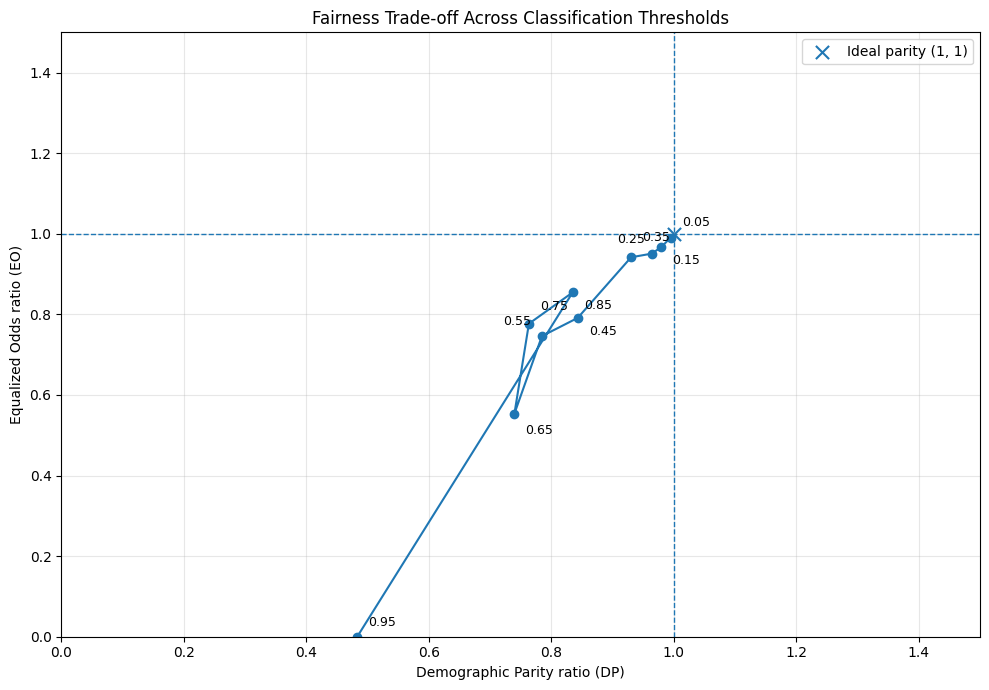

In [ ]:
plt.figure(figsize=(10, 7))

plt.plot(
    verified_fairness_results["DP"],
    verified_fairness_results["EO"],
    marker="o",
    linewidth=1.5
)

# Label each threshold with alternating offsets to reduce overlap
offsets = [
    (8, 8), (8, -12), (-25, 8), (8, 12), (8, -12),
    (-28, 8), (8, -15), (8, 10), (8, -12), (8, 8)
]

for i, (_, row) in enumerate(verified_fairness_results.iterrows()):
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP"], row["EO"]),
        xytext=offsets[i],
        textcoords="offset points",
        fontsize=9
    )

plt.axvline(1.0, linestyle="--", linewidth=1)
plt.axhline(1.0, linestyle="--", linewidth=1)
plt.scatter([1], [1], marker="x", s=90, label="Ideal parity (1, 1)")

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity ratio (DP)")
plt.ylabel("Equalized Odds ratio (EO)")
plt.title("Fairness Trade-off Across Classification Thresholds")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

1. Explanation of the fairness metrics
The fairness analysis compares groups A92 and A93 from the personal_status_sex feature in the German Credit dataset. The test set contains 94 A92 cases and 176 A93 cases. Since this feature combines personal status and sex, these categories should not be interpreted as pure gender groups.
- Demographic Parity (DP): compares the proportion of positive predictions between the two groups. A ratio close to 1 indicates similar positive prediction rates.
- Equalized Odds (EO): for this assignment, EO is calculated as the minimum of the TPR ratio and FPR ratio between groups. A value close to 1 suggests greater parity in these error-rate measures.
- Predictive Parity (PP): compares precision between the groups. A ratio close to 1 indicates similar precision, meaning positive predictions have similar correctness rates across the groups.
A ratio of 1 represents parity for the corresponding metric. However, parity does not automatically mean that the model is accurate or that its decisions are appropriate.
2. Interpretation of the results
At threshold 0.05, DP is 0.995 and EO is 0.991, both very close to 1. This suggests similar positive prediction rates and relatively similar error-rate ratios between A92 and A93. However, such a low threshold classifies nearly all cases as positive, so this result should not be interpreted as proof that the model is fair overall.
At threshold 0.35, DP is 0.930, EO is 0.942, and PP is 0.896. These values remain relatively close to 1, indicating a more balanced result across the three measured ratios than at some higher thresholds. Nevertheless, the metrics do not establish that this threshold is optimal; predictive performance and the consequences of incorrect classifications must also be considered.
At threshold 0.55, DP decreases to 0.785 and EO to 0.746. This indicates that the groups differ more substantially in their positive prediction rates and in at least one of the error-rate ratios. At threshold 0.65, EO drops further to 0.554, even though PP is 1.003. This illustrates that predictive parity can be close to equality while error-rate parity remains considerably different.
At threshold 0.95, DP is 0.483 and EO is 0.000. The zero EO value occurs because the A92 false-positive rate is zero while the A93 false-positive rate is nonzero. The groups therefore do not have equal error-rate ratios at this threshold. The high threshold also produces very few positive predictions, so the result needs to be interpreted alongside the model's ability to identify actual positive cases.
3. Explaining the trade-off shown in the plot
The plot shows how DP and EO change as the classification threshold increases. The ideal reference point is (1, 1), where both ratios indicate parity. The threshold 0.05 lies closest to this point among the tested thresholds, while the point for 0.95 lies far away.
This pattern demonstrates that the choice of threshold affects fairness measurements. A threshold that performs well under one fairness criterion may perform poorly under another. Therefore, selecting a threshold should involve more than choosing the point nearest to (1, 1): the model's accuracy, false-positive and false-negative rates, and the real-world impact of decisions should also be considered.
4. Recommendation and limitations
Based on these results, threshold 0.35 could be discussed as a candidate for further evaluation, because its DP and EO ratios are both reasonably close to 1 and its PP ratio is 0.896. This is not a definitive recommendation: compare accuracy and error rates at this threshold with those at other thresholds before selecting it.
The analysis has limitations. First, it compares only A92 and A93 rather than every category of personal_status_sex. Second, the groups are unequal in size, and the smaller group has only 94 test cases, which can make estimated fairness metrics sensitive to a small number of predictions. Finally, the observed ratios describe this particular test set and do not prove that the model will behave similarly on other populations.
Overall conclusion: The fairness metrics vary with the classification threshold, demonstrating a trade-off between different notions of fairness. A responsible threshold choice should balance parity, predictive performance, and the consequences of classification errors, rather than relying on a single fairness ratio.A numerical comparison between thresholds 0.35 and 0.55 illustrates the trade-off. Predictive parity (PP) increased from 0.896 to 0.954, a relative improvement of approximately 6.47%. However, equalized odds (EO) decreased from 0.942 to 0.746, a relative decline of approximately 20.81%, while demographic parity (DP) also decreased from 0.930 to 0.785. The relative EO decline is about 3.22 times the relative PP improvement. This comparison demonstrates that improving predictive parity can coincide with worse equalized odds and demographic parity. It does not demonstrate a DP improvement accompanied by an EO decline; the results for these two thresholds show both DP and EO decreasing. Therefore, the trade-off should be described using the metrics and directions actually observed in the analysis.